In [1]:
from ase.io import read, write
from ase.visualize import view
import nglview
import pymbar
import numpy as np
from pathlib import Path
from pymbar import timeseries, MBAR
import matplotlib.pyplot as plt
from ase.units import kB
from pymbar.utils import kln_to_kn

Warning on use of the timeseries module: If the inherent timescales of the system are long compared to those being analyzed, this statistical inefficiency may be an underestimate.  The estimate presumes the use of many statistically independent samples.  Tests should be performed to assess whether this condition is satisfied.   Be cautious in the interpretation of the data.

********* JAX NOT FOUND *********
 PyMBAR can run faster with JAX  
 But will work fine without it   
Either install with pip or conda:
      pip install pybar[jax]     
               OR                
      conda install pymbar       
*********************************


In [2]:
first_window = read("traj_files/traj_window_12_cv_-0.73.traj", index=":")

v = view(first_window, viewer='ngl')

# Use v.view if ASE wraps the widget in an HBox/VBox, otherwise use v directly
widget = v.view if hasattr(v, 'view') else v
widget.clear_representations()
widget.add_representation("ball+stick", scale=0.75)
widget.add_label(
    color="black",
    labelType="text",
    labelText=[str(i) for i in range(len(first_window))],
    zOffset=1.0,
    attachment="middle_center",
    radius=0.8
)
v

# Window Correlation Analysis with pymbar

equil. frames: 23 g: 6.321947 indep. samples: 155
Collective Variable Mean:  1.144471653801705
Collective Variable Standard Deviation:  0.08655526569616856


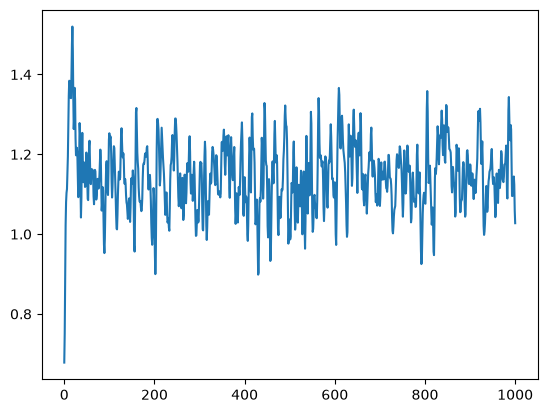

In [3]:
from pymbar import timeseries, MBAR
import numpy as np
import matplotlib.pyplot as plt

window_traj = "traj_files/traj_window_26_cv_0.68.traj" # Enter window trajectory
window = read(window_traj, index=":")

kB = 0.0083144626
T = 25 + 273.15
beta = 1.0 / (kB * T)

cv_k = np.zeros(len(window))

i = 0

for atoms in window:
    d = atoms.get_distance(4, 6, mic=True) - atoms.get_distance(4, 21, mic=True)
    cv_k[i] = d
    i += 1

sub_cv = []

t0, g, neff = timeseries.detect_equilibration(cv_k)
x_eq = cv_k[t0:]
idx = timeseries.subsample_correlated_data(x_eq, g=g)
sub_cv.append(x_eq[idx])
print("equil. frames:", t0, "g:", g, "indep. samples:", len(idx))
print("Collective Variable Mean: ",np.mean(cv_k))
print("Collective Variable Standard Deviation: ",np.std(cv_k))
plt.plot(cv_k)
plt.show()

# Summary of Stats Correlation Data:

## 1st  Image: equil. frames: 0  g: 116.84275 indep. samples: 172
## 9th  Image: equil. frames: 10 g: 3.4489763 indep. samples: 288
## 16th Image: equil. frames: 64 g: 1.4240708 indep. samples: 658
## 26th Image: equil. frames: 0  g: 3.2685254 indep. samples: 307
## 36th Image: equil. frames: 0  g: 7.4876857 indep. samples: 134

In [4]:
plt.plot(cv_0s, cv_xs_means, "o-")
plt.plot(cv_0s, cv_0s, "k--", label="mean = center")
plt.plot(cv_0s[17], cv_xs_means[17], "o-", c="red")
plt.xlabel("restraint center ξ₀")
plt.ylabel("mean sampled ξ")
plt.legend()
plt.show()

NameError: name 'cv_0s' is not defined

In [5]:
plt.hist(cv_xs_means, bins=50, histtype="step", density=False)
plt.xlabel("ξ")
plt.ylabel("counts")
plt.show()

NameError: name 'cv_xs_means' is not defined

In [8]:
all_frames = []
traj_files = sorted(Path('traj_files/').glob('traj_window_*_cv_*.traj'))
n_frames_per_win = 1001
n_windows = len(traj_files)
N_k = np.full(n_windows, n_frames_per_win, dtype=int)
n_total = N_k.sum()
u_kn = np.zeros((n_windows, n_total), dtype=float)
T = 300  # Kelvin
beta = 1.0 / (kB * T)

cv_0s = np.loadtxt('centers.txt')
kappa_k = np.full(n_windows, 2.073)
kappa_k[:30] = 10.364

cv_xs = np.zeros((n_windows, n_frames_per_win), dtype=float)
cv_xs_means = np.zeros(n_windows, dtype=float)
all_cvs = np.zeros(n_total, dtype=float)
all_epot = np.zeros(n_total, dtype=float)

col = 0
for i, traj_file in enumerate(traj_files): 
    window = read(str(traj_file), index=":")
    if len(window) != n_frames_per_win:
        raise ValueError(
            f"Window {i} ({traj_file}) has {len(window)} frames; expected {n_frames_per_win}."
        )
    for j, atoms in enumerate(window):
        d = atoms.get_distance(4, 6, mic=True) - atoms.get_distance(4, 21, mic=True)
        epot = float(np.asarray(atoms.get_potential_energy()).item())
        
        cv_xs[i,j] = d
        all_cvs[col] = d
        all_epot[col] = epot
        col += 1
        
        #all_frames.append(atoms)
        
    cv_xs_means[i] = cv_xs[i].mean()

u_unbiased = beta * all_epot[None, :]  # shape (1, n_total)
u_bias_kn = beta * 0.5 * kappa_k[:, None] * (all_cvs[None, :] - cv_0s[:, None]) ** 2
u_kn = u_unbiased + u_bias_kn

assert u_kn.shape == (n_windows, n_total), f"Unexpected u_kn shape: {u_kn.shape}"

mbar = MBAR(u_kn, N_k, initialize="BAR", solver_protocol="robust")

In [9]:
n_windows

79

Saving outputs in: /home/ichop/aspirin_hydrolysis/transition_path_search/mace_dynamics/umbrella_sampling
Raw mu from compute_multiple_expectations: [1.31618961e-02 6.85475857e-02 3.26433230e-02 2.09928753e-03
 6.77850585e-04 1.04712445e-02 2.19141734e-02 9.78404571e-03
 1.20402679e-02 1.98178659e-02 1.55534658e-02 1.83198917e-02
 2.03118372e-02 2.18573797e-02 2.32377062e-02 2.44338694e-02
 2.63883181e-02 3.28354196e-02 6.13839974e-02 4.26490175e-02
 7.46733584e-03 3.70731666e-05 1.47303237e-05 1.66900458e-02
 3.64970825e-02 1.79202020e-02 2.80108006e-03 8.12166332e-05
 8.97143170e-03 7.35043690e-02 6.01118946e-02 3.02793164e-02
 4.26855604e-02 1.26741169e-01 6.30987089e-02 1.41667115e-02
 1.39937769e-02 6.43280707e-03 3.77045212e-04]
Valid PMF bins: 39 / 40
  d =  -4.317 Å   F =   5.6492 eV   (n=209)
  d =  -4.139 Å   F =   1.5331 eV   (n=1164)
  d =  -3.962 Å   F =   3.3836 eV   (n=589)
  d =  -3.784 Å   F =  10.2282 eV   (n=40)
  d =  -3.428 Å   F =  13.0478 eV   (n=15)
  d =  -3.250

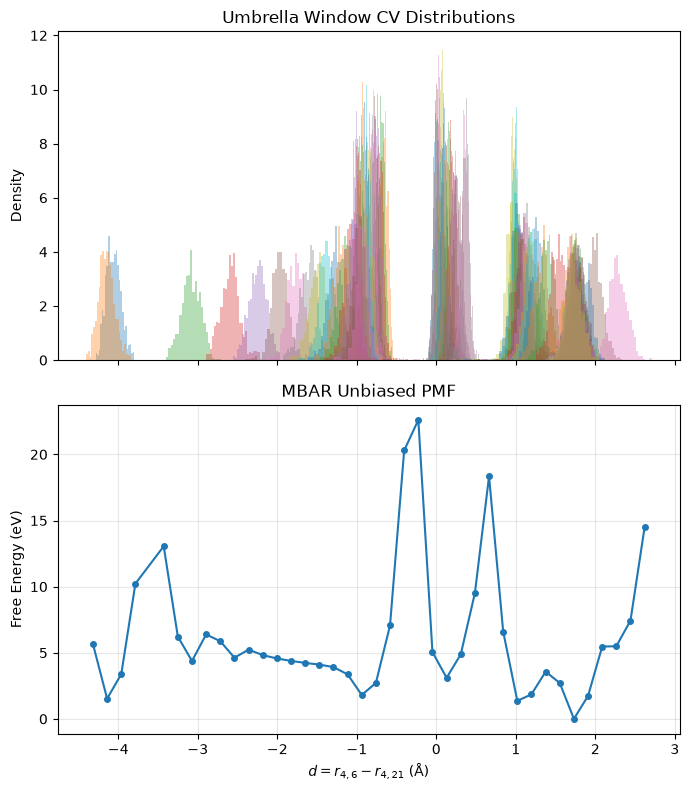

<Figure size 640x480 with 0 Axes>

In [10]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np

print("Saving outputs in:", os.getcwd())

u_unbiased_n = beta * all_epot

n_bins = 40
bin_edges = np.linspace(all_cvs.min(), all_cvs.max(), n_bins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
bin_idx = np.clip(np.digitize(all_cvs, bin_edges) - 1, 0, n_bins - 1)

counts = np.bincount(bin_idx, minlength=n_bins)
active_bins = np.flatnonzero(counts > 0)
A_active = (bin_idx[None, :] == active_bins[:, None]).astype(float)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    exp_res = mbar.compute_multiple_expectations(A_active, u_unbiased_n)

probs_active = np.asarray(exp_res["mu"], dtype=float)
print("Raw mu from compute_multiple_expectations:", probs_active)

probs = np.zeros(n_bins, dtype=float)
probs[active_bins] = np.where(np.isfinite(probs_active) & (probs_active > 0), probs_active, 0.0)

f_i_kt = np.full(n_bins, np.nan, dtype=float)
pos = probs > 0
f_i_kt[pos] = -np.log(probs[pos])

f_ev = f_i_kt / beta
min_f = np.nanmin(f_ev) if np.any(pos) else 0.0
f_ev_shifted = f_ev - min_f

print(f"Valid PMF bins: {pos.sum()} / {n_bins}")
for c, f, cnt in zip(bin_centers, f_ev_shifted, counts):
    if np.isfinite(f):
        print(f"  d = {c:+7.3f} Å   F = {f:8.4f} eV   (n={cnt})")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 8), sharex=True)
for i in range(n_windows):
    ax1.hist(cv_xs[i], bins=25, density=True, alpha=0.35)
ax1.set_ylabel("Density")
ax1.set_title("Umbrella Window CV Distributions")

if np.any(pos):
    ax2.plot(bin_centers[pos], f_ev_shifted[pos], marker="o", markersize=4)
else:
    ax2.text(0.5, 0.5, "No positive bin probabilities returned", ha="center", va="center", transform=ax2.transAxes)

ax2.set_xlabel(r"$d = r_{4,6} - r_{4,21}$ (Å)")
ax2.set_ylabel("Free Energy (eV)")
ax2.set_title("MBAR Unbiased PMF")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig("pmf_mbar.png", dpi=300)
plt.close(fig)

### Next steps: Run more trajectories where you see gaps in the histogram to get a better idea of barrier height.

In [12]:
mbar.compute_overlap()["matrix"]

array([[0.02914559, 0.02150927, 0.02027172, ..., 0.00487919, 0.00495332,
        0.0049908 ],
       [0.02150927, 0.02794769, 0.02829812, ..., 0.00210777, 0.00216212,
        0.00218982],
       [0.02027172, 0.02829812, 0.02885535, ..., 0.00191453, 0.00196663,
        0.00199321],
       ...,
       [0.00487919, 0.00210777, 0.00191453, ..., 0.02809988, 0.02799205,
        0.02793758],
       [0.00495332, 0.00216212, 0.00196663, ..., 0.02799205, 0.0278857 ,
        0.02783197],
       [0.0049908 , 0.00218982, 0.00199321, ..., 0.02793758, 0.02783197,
        0.02777862]], shape=(79, 79))

In [13]:
import numpy as np

ov_out = mbar.compute_overlap()
ov_mat = np.real(ov_out["matrix"])
ov_scalar = np.real(ov_out["scalar"])

print(f"Global scalar overlap: {ov_scalar:.4f}")
print("Matrix shape:", ov_mat.shape)

# Nearest-neighbor overlap along the ordered windows
nn_overlap = np.diag(ov_mat, k=1)
for k, val in enumerate(nn_overlap):
    flag = "  <-- LOW / ZERO OVERLAP" if val < 0.02 else ""
    print(f"Pair ({k:02d}, {k+1:02d}): overlap = {val:.4f}{flag}")

Global scalar overlap: 0.2848
Matrix shape: (79, 79)
Pair (00, 01): overlap = 0.0215
Pair (01, 02): overlap = 0.0283
Pair (02, 03): overlap = 0.0292
Pair (03, 04): overlap = 0.0299
Pair (04, 05): overlap = 0.0307
Pair (05, 06): overlap = 0.0315
Pair (06, 07): overlap = 0.0323
Pair (07, 08): overlap = 0.0330
Pair (08, 09): overlap = 0.0336
Pair (09, 10): overlap = 0.0342
Pair (10, 11): overlap = 0.0347
Pair (11, 12): overlap = 0.0352
Pair (12, 13): overlap = 0.0357
Pair (13, 14): overlap = 0.0362
Pair (14, 15): overlap = 0.0112  <-- LOW / ZERO OVERLAP
Pair (15, 16): overlap = 0.0297
Pair (16, 17): overlap = 0.0299
Pair (17, 18): overlap = 0.0301
Pair (18, 19): overlap = 0.0302
Pair (19, 20): overlap = 0.0301
Pair (20, 21): overlap = 0.0299
Pair (21, 22): overlap = 0.0297
Pair (22, 23): overlap = 0.0292
Pair (23, 24): overlap = 0.0287
Pair (24, 25): overlap = 0.0283
Pair (25, 26): overlap = 0.0275
Pair (26, 27): overlap = 0.0275
Pair (27, 28): overlap = 0.0244
Pair (28, 29): overlap = 0.